# Lesson 15. The color from the other side

[Course plan](../../README.md)

A gray ball stays gray as the camera travels around it. Yet a small patch on a glazed cup can look redder in one photograph than in the next. The same stationary part of a scene can have different observed colors. We start with a splat whose red channel alone can vary.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## A frame where only the color changes

The camera always aims at the center of one round splat with equal scale along all three axes. The distance stays fixed as well. On the left the splat has a fixed RGB. On the right a direction-dependent value is added to the same RGB. Opacity at the center is one, so this pixel shows the splat color itself. Near the edges the white background mixes in.

With all three directional coefficients at zero, the right frame matches the left at every azimuth. One nonzero coefficient reveals which side of the sphere gains red. Elevating the camera introduces a vertical component.

In [2]:
display(demo.experiment(15, "en"))

## A direction of length one

In a numerical example the camera center is $K=(-3,0,0)$ and the splat center is $P=(0,0,4)$. The arrow **from camera to splat** is $P-K=(3,0,4)$. Its length by Pythagoras is $r=\sqrt{3^2+0^2+4^2}=\sqrt{25}=5$. Dividing each component by five gives $d=(0.6,0,0.8)$. Its length is now one because $0.6^2+0.8^2=1$. Direction has no units, and distance alone no longer changes the color. A camera another five units back along the same line yields the same normalized arrow.

The tips of all such unit arrows lie on a sphere. A camera exactly at the splat center would yield a zero arrow and no direction. The renderer already skips that center in its depth test. Positive $y$ points down in the initial camera's world. Color coefficients refer to world axes, so turning the camera body in place does not by itself change the color of a point.

In [3]:
direction = np.array([3., 0., 4.])
print(direction / np.linalg.norm(direction))
print(np.round(sr.sh_basis(direction), 6))
np.testing.assert_allclose(sr.sh_basis(direction), sr.sh_basis(2*direction))

[0.6 0.  0.8]
[ 0.282095 -0.        0.390882 -0.293162]


## Four maps on the same sphere

A **spherical harmonic** here is a fixed rule that returns a number for a direction. The collection of these rules forms a basis. The first map has one value everywhere on the sphere. Three more maps change sign smoothly between opposite sides. A **function** determines the pattern on each map. A **coefficient** says how much of that pattern belongs to one splat's color.

The renderer of Kerbl et al. uses the first four real functions in this order:

$$
(Y_0,Y_y,Y_z,Y_x)=(C_0,-C_1d_y,+C_1d_z,-C_1d_x).
$$

Here $C_0=1/\sqrt{4\pi}\approx0.282095$ and $C_1=\sqrt{3/(4\pi)}\approx0.488603$. The number $\pi\approx3.14159$ relates a circle's radius and circumference. These constants give each function the same total squared value across the sphere. For a unit sphere the area is $4\pi$. The constant map gives $4\pi C_0^2=1$. For the $x$ map, the average of $x^2$ over the sphere is $1/3$: the axes are equivalent and $x^2+y^2+z^2=1$. Thus $4\pi C_1^2/3=1$. In the image the normalization constant and the learned coefficient always act together.

At $(0.6,0,0.8)$ the four map values are $(0.282095,0,0.390882,-0.293162)$. A negative basis value is useful. It subtracts a contribution from the channel before we turn that channel into a display intensity.

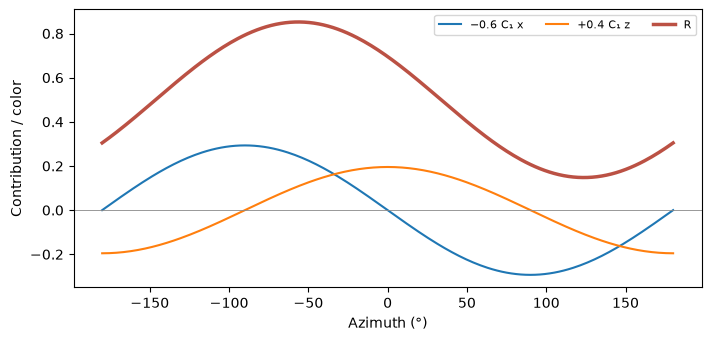

In [4]:
fig = demo.harmonic_curve("en")
display(fig)
plt.close(fig)

## From the maps to the red channel

The example uses four coefficients for red, $a=(0,0,0.4,0.6)$. In the original GS encoding a constant offset of $0.5$ gives gray when all coefficients are zero. We multiply each basis value by its coefficient and add:

$$
\begin{aligned}
R &= 0.5+a_0Y_0+a_yY_y+a_zY_z+a_xY_x \\
  &= 0.5+0+0+0.4\cdot0.390882+0.6\cdot(-0.293162)\\
  &\approx 0.5+0.156353-0.175897=0.480456.
\end{aligned}
$$

Green and blue have zero coefficients and the resulting triple is $(0.480456,0.5,0.5)$. For a constant red of $0.8$, we solve $0.8=0.5+a_0 C_0$. Subtracting $0.5$ and dividing $0.3$ by $0.282095$ gives $a_0\approx1.0635$. A coefficient can exceed one. For display we clip each final channel to $[0,1]$. At this stage the original CUDA SH calculation clips only negative values. The location of that clamp matters when training with very bright colors.

In [5]:
coeff = np.array([[0,0,0], [0,0,0], [.4,0,0], [.6,0,0]])
for d in ([.6,0,.8], [-.6,0,-.8]):
    print(d, np.round(sr.sh_color(d, coeff), 6))
constant = [[(.8-.5)/sr.C0, 0, 0]]
np.testing.assert_allclose(sr.sh_color([0,0,1], constant), [.8,.5,.5])

[0.6, 0, 0.8] [0.480456 0.5      0.5     ]
[-0.6, 0, -0.8] [0.519544 0.5      0.5     ]


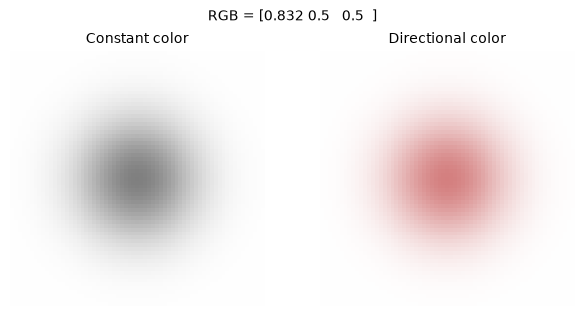

In [6]:
fig = demo.harmonic_figure("en")
display(fig)
plt.close(fig)

## How many values a splat stores

The constant map has degree zero. Degree one adds three maps. Through degree $l$ there are $(l+1)^2$ maps in total. At $l=1$ we get $(1+1)^2=4$ coefficients per channel and $4\cdot3=12$ numbers for RGB. At $l=3$ there are $16\cdot3=48$. Higher degrees allow color to vary more rapidly with direction. A very narrow highlight still takes more angular detail than a few smooth maps can reproduce. The coefficients are fitted to photographs. They describe an observed dependence and do not determine the position of a lamp. [Direction and signs in the original renderer](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu).

## Experiments and worked answers

What does the opposite side of the sphere look like? How could the model switch to a splat-to-camera arrow while preserving its appearance?

<details><summary>Worked answer</summary>

At the opposite direction all three linear maps reverse sign. Red becomes $0.5-0.156353+0.175897=0.519544$. Degree zero is identical on both sides. To translate the model between opposite conventions, we also reverse the signs of its three degree-one coefficients. The two minus signs in each product cancel.

</details>